In [2]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer

# Load dataset
data = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

# Inspect dataset
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())

Shape: (569, 31)

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Target distribution:
target
1    357
0    212
Name: count, dtype: int64

Missing values:
0


In [3]:
X = df.drop("target", axis=1)
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature data types:")
print(X.dtypes.value_counts())

print("\nMissing values:", X.isnull().sum().sum())

X shape: (569, 30)
y shape: (569,)

Feature data types:
float64    30
Name: count, dtype: int64

Missing values: 0


In [4]:
X_engineered = X.copy()

X_engineered["radius_range"] = (
    X_engineered["worst radius"] - X_engineered["mean radius"]
)

X_engineered["area_range"] = (
    X_engineered["worst area"] - X_engineered["mean area"]
)

X_engineered["compactness_concavity_ratio"] = (
    X_engineered["mean compactness"] /
    (X_engineered["mean concavity"] + 1e-8)
)

print("Original features:", X.shape[1])
print("New feature count:", X_engineered.shape[1])

print("\nNew feature preview:")
display(X_engineered[
    ["radius_range", "area_range", "compactness_concavity_ratio"]
].head())

print("\nMissing values:", X_engineered.isnull().sum().sum())

Original features: 30
New feature count: 33

New feature preview:


,radius_range,area_range,compactness_concavity_ratio
0,7.39,1018.0,0.925025
1,4.42,630.0,0.904948
2,3.88,506.0,0.810030
3,3.49,181.6,1.176056
4,2.25,278.0,0.670707



Missing values: 0


In [5]:
from sklearn.feature_selection import VarianceThreshold

# Calculate variance
variances = X_engineered.var().sort_values()

print("10 features with lowest variance:")
display(variances.head(10))

print("\n10 features with highest variance:")
display(variances.tail(10))

10 features with lowest variance:


fractal dimension error    0.000007
smoothness error           0.000009
concave points error       0.000038
mean fractal dimension     0.000050
symmetry error             0.000068
mean smoothness            0.000198
compactness error          0.000321
worst fractal dimension    0.000326
worst smoothness           0.000521
mean symmetry              0.000752
dtype: float64


10 features with highest variance:


mean texture                   1.849891e+01
worst radius                   2.336022e+01
worst texture                  3.777648e+01
mean perimeter                 5.904405e+02
worst perimeter                1.129131e+03
area error                     2.069432e+03
area_range                     6.362582e+04
mean area                      1.238436e+05
worst area                     3.241674e+05
compactness_concavity_ratio    5.435907e+11
dtype: float64

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_engineered)

# Apply variance threshold
selector = VarianceThreshold(threshold=0.01)
X_selected = selector.fit_transform(X_scaled)

selected_features = X_engineered.columns[selector.get_support()]

print("Original feature count:", X_engineered.shape[1])
print("Selected feature count:", X_selected.shape[1])
print("Removed feature count:",
      X_engineered.shape[1] - X_selected.shape[1])

print("\nRemoved features:")
print(X_engineered.columns[~selector.get_support()].tolist())

Original feature count: 33
Selected feature count: 33
Removed feature count: 0

Removed features:
[]


In [7]:
selector_raw = VarianceThreshold(threshold=0.01)

X_raw_selected = selector_raw.fit_transform(X_engineered)

raw_selected_features = X_engineered.columns[
    selector_raw.get_support()
]

print("Original features:", X_engineered.shape[1])
print("Selected features:", X_raw_selected.shape[1])
print("Removed features:",
      X_engineered.columns[
          ~selector_raw.get_support()
      ].tolist())

Original features: 33
Selected features: 17
Removed features: ['mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst smoothness', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [8]:
from sklearn.feature_selection import SelectKBest, f_classif

selector_kbest = SelectKBest(
    score_func=f_classif,
    k=10
)

X_kbest = selector_kbest.fit_transform(X_engineered, y)

kbest_features = X_engineered.columns[
    selector_kbest.get_support()
]

# Display selected features and their scores
feature_scores = pd.DataFrame({
    "Feature": X_engineered.columns,
    "F_Score": selector_kbest.scores_,
    "Selected": selector_kbest.get_support()
}).sort_values("F_Score", ascending=False)

print("Selected 10 features:")
print(kbest_features.tolist())

print("\nFeature ranking:")
display(feature_scores)

Selected 10 features:
['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concave points', 'radius_range']

Feature ranking:


,Feature,F_Score,Selected
27,worst concave points,964.385393,True
22,worst perimeter,897.944219,True
7,mean concave points,861.676020,True
20,worst radius,860.781707,True
2,mean perimeter,697.235272,True
23,worst area,661.600206,True
0,mean radius,646.981021,True
30,radius_range,581.094494,True
3,mean area,573.060747,True
6,mean concavity,533.793126,True


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_engineered,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training shape: (455, 33)
Testing shape: (114, 33)

Training target distribution:
target
1    0.626374
0    0.373626
Name: proportion, dtype: float64

Testing target distribution:
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Model A: All 33 features
model_all = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Model B: Select top 10 features
model_selected = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_classif, k=10)),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train both models
model_all.fit(X_train, y_train)
model_selected.fit(X_train, y_train)

# Predictions
pred_all = model_all.predict(X_test)
pred_selected = model_selected.predict(X_test)

# Compare
print("All 33 features accuracy:",
      accuracy_score(y_test, pred_all))

print("Selected 10 features accuracy:",
      accuracy_score(y_test, pred_selected))

print("\nSelected features learned from training data:")
print(
    X_train.columns[
        model_selected.named_steps["selector"].get_support()
    ].tolist()
)

print("\nClassification report — All features:")
print(classification_report(y_test, pred_all))

print("\nClassification report — Selected features:")
print(classification_report(y_test, pred_selected))

All 33 features accuracy: 0.9824561403508771
Selected 10 features accuracy: 0.9736842105263158

Selected features learned from training data:
['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concave points', 'radius_range']

Classification report — All features:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Classification report — Selected features:
              precision    recall  f1-score   support

           0       0.98      0.95      0.96        42
           1       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate all 33 features
cv_all = cross_val_score(
    model_all,
    X_engineered,
    y,
    cv=cv,
    scoring="accuracy"
)

# Evaluate selected 10 features
cv_selected = cross_val_score(
    model_selected,
    X_engineered,
    y,
    cv=cv,
    scoring="accuracy"
)

print("All 33 features:")
print("Fold scores:", cv_all)
print("Mean accuracy:", cv_all.mean())
print("Standard deviation:", cv_all.std())

print("\nSelected 10 features:")
print("Fold scores:", cv_selected)
print("Mean accuracy:", cv_selected.mean())
print("Standard deviation:", cv_selected.std())

All 33 features:
Fold scores: [0.97368421 0.93859649 0.96491228 0.99122807 0.99115044]
Mean accuracy: 0.971914299021891
Standard deviation: 0.01952069739894481

Selected 10 features:
Fold scores: [0.98245614 0.93859649 0.94736842 0.96491228 0.96460177]
Mean accuracy: 0.9595870206489675
Standard deviation: 0.015273501512104746


In [12]:
# Correlation matrix
corr_matrix = X_engineered.corr().abs()

# Upper triangle to avoid duplicate pairs
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find pairs with correlation above 0.90
high_corr_pairs = (
    upper.stack()
    .reset_index()
)

high_corr_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Correlation"] > 0.90
].sort_values("Correlation", ascending=False)

display(high_corr_pairs)


,Feature 1,Feature 2,Correlation
2,mean radius,mean perimeter,0.997855
682,worst radius,worst perimeter,0.993708
3,mean radius,mean area,0.987357
69,mean perimeter,mean area,0.986507
683,worst radius,worst area,0.984015
749,worst perimeter,worst area,0.977578
342,radius error,perimeter error,0.972794
1021,radius_range,area_range,0.971715
88,mean perimeter,worst perimeter,0.970387
20,mean radius,worst radius,0.969539


In [13]:
# Identify features involved in correlations above 0.95
threshold = 0.95

to_drop = [
    column
    for column in upper.columns
    if any(upper[column] > threshold)
]

print("Features to consider removing:")
print(to_drop)

print("\nNumber of features to consider removing:", len(to_drop))


Features to consider removing:
['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area', 'area_range']

Number of features to consider removing: 8


In [14]:
X_reduced = X_engineered.drop(columns=to_drop)

print("Original shape:", X_engineered.shape)
print("Reduced shape:", X_reduced.shape)
print("Removed features:", len(to_drop))

Original shape: (569, 33)
Reduced shape: (569, 25)
Removed features: 8


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# Same split for both datasets
X_train, X_test, y_train, y_test = train_test_split(
    X_engineered,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train_reduced = X_train.drop(columns=to_drop)
X_test_reduced = X_test.drop(columns=to_drop)

# Baseline model
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

baseline_model.fit(X_train, y_train)

# Reduced model
reduced_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

reduced_model.fit(X_train_reduced, y_train)

# Compare
for name, model, X_eval in [
    ("Baseline", baseline_model, X_test),
    ("Reduced", reduced_model, X_test_reduced)
]:
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]

    print(f"\n{name} Model")
    print(classification_report(y_test, predictions))
    print("ROC-AUC:", roc_auc_score(y_test, probabilities))


Baseline Model
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

ROC-AUC: 0.9966931216931216

Reduced Model
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

ROC-AUC: 0.9966931216931216


In [16]:
from sklearn.model_selection import train_test_split
import numpy as np

# Split original engineered dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_engineered,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Calculate correlations using training data only
corr_train = X_train.corr().abs()

upper_train = corr_train.where(
    np.triu(np.ones(corr_train.shape), k=1).astype(bool)
)

# Identify highly correlated features
to_drop_train = [
    column
    for column in upper_train.columns
    if any(upper_train[column] > 0.95)
]

# Apply the same selection to train and test
X_train_selected = X_train.drop(columns=to_drop_train)
X_test_selected = X_test.drop(columns=to_drop_train)

print("Training features:", X_train.shape[1])
print("Selected features:", X_train_selected.shape[1])
print("Removed features:", to_drop_train)

Training features: 33
Selected features: 25
Removed features: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area', 'area_range']


In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

selected_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

selected_model.fit(X_train_selected, y_train)

# Predictions
y_pred = selected_model.predict(X_test_selected)
y_prob = selected_model.predict_proba(X_test_selected)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

ROC-AUC: 0.9966931216931216


In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    confusion_matrix
)

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_selected, y_train)

# Predictions
rf_pred = rf_model.predict(X_test_selected)
rf_prob = rf_model.predict_proba(X_test_selected)[:, 1]

print("Classification Report:")
print(classification_report(y_test, rf_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        42
           1       1.00      1.00      1.00        72

    accuracy                           1.00       114
   macro avg       1.00      1.00      1.00       114
weighted avg       1.00      1.00      1.00       114

Confusion Matrix:
[[42  0]
 [ 0 72]]
ROC-AUC: 1.0


In [19]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train_selected.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
23,radius_range,0.183829
20,worst concave points,0.172370
5,mean concave points,0.134466
0,mean radius,0.097097
4,mean concavity,0.087509
24,compactness_concavity_ratio,0.075778
19,worst concavity,0.048281
8,radius error,0.027499
18,worst compactness,0.022549
16,worst texture,0.019373


In [20]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train_selected,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    print(f"\n{name}")
    print("Fold scores:", scores)
    print("Mean accuracy:", scores.mean())
    print("Standard deviation:", scores.std())


Logistic Regression
Fold scores: [0.94505495 0.97802198 0.97802198 0.98901099 0.96703297]
Mean accuracy: 0.9714285714285713
Standard deviation: 0.014906219743132469

Random Forest
Fold scores: [0.95604396 0.97802198 0.95604396 0.97802198 0.97802198]
Mean accuracy: 0.9692307692307691
Standard deviation: 0.01076698788036558


In [21]:
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin

class CorrelationSelector(BaseEstimator, TransformerMixin):

    def __init__(self, threshold=0.95):
        self.threshold = threshold

    def fit(self, X, y=None):
        corr = X.corr().abs()

        upper = corr.where(
            np.triu(np.ones(corr.shape), k=1).astype(bool)
        )

        self.to_drop_ = [
            column
            for column in upper.columns
            if any(upper[column] > self.threshold)
        ]

        self.feature_names_in_ = X.columns.tolist()
        return self

    def transform(self, X):
        return X.drop(columns=self.to_drop_)

    def get_feature_names_out(self, input_features=None):
        return np.array([
            col for col in self.feature_names_in_
            if col not in self.to_drop_
        ])

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": Pipeline([
        ("selector", CorrelationSelector(threshold=0.95)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Random Forest": Pipeline([
        ("selector", CorrelationSelector(threshold=0.95)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    print(f"\n{name}")
    print("Fold scores:", scores)
    print("Mean accuracy:", scores.mean())
    print("Standard deviation:", scores.std())


Logistic Regression
Fold scores: [0.94505495 0.97802198 0.97802198 0.98901099 0.96703297]
Mean accuracy: 0.9714285714285713
Standard deviation: 0.014906219743132469

Random Forest
Fold scores: [0.95604396 0.97802198 0.95604396 0.97802198 0.97802198]
Mean accuracy: 0.9692307692307691
Standard deviation: 0.01076698788036558


In [23]:
from sklearn.metrics import confusion_matrix, classification_report

# Fit using training data
final_lr = models["Logistic Regression"]
final_lr.fit(X_train, y_train)

# Probability of class 0 (malignant)
malignant_prob = final_lr.predict_proba(X_test)[:, 0]

for threshold in [0.3, 0.5, 0.7]:

    predictions = (malignant_prob >= threshold).astype(int)

    # Convert 1/0 flags back to original labels
    predictions = 1 - predictions

    print(f"\nThreshold: {threshold}")
    print(confusion_matrix(y_test, predictions))
    print(classification_report(y_test, predictions))


Threshold: 0.3
[[41  1]
 [ 3 69]]
              precision    recall  f1-score   support

           0       0.93      0.98      0.95        42
           1       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114


Threshold: 0.5
[[41  1]
 [ 1 71]]
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Threshold: 0.7
[[40  2]
 [ 0 72]]
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        42
           1       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99

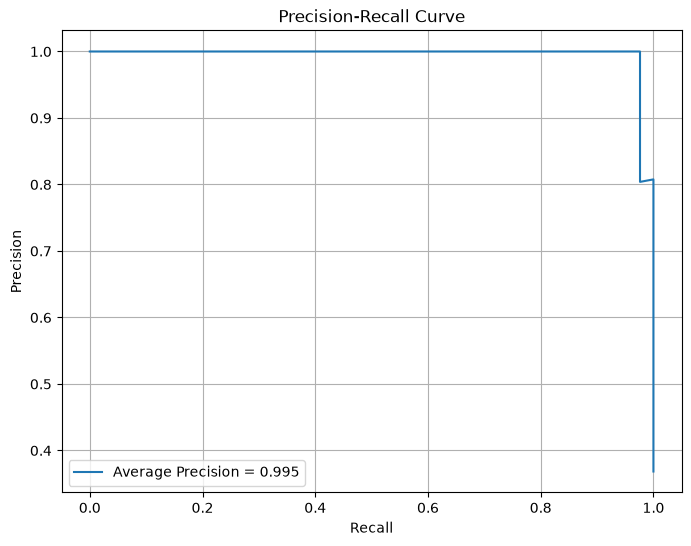

Average Precision: 0.9954212454212454


In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# Probability of malignant (class 0)
malignant_prob = final_lr.predict_proba(X_test)[:, 0]

# Convert labels: malignant = 1, benign = 0
y_malignant = (y_test == 0).astype(int)

precision, recall, thresholds = precision_recall_curve(
    y_malignant,
    malignant_prob
)

ap = average_precision_score(y_malignant, malignant_prob)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f"Average Precision = {ap:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

print("Average Precision:", ap)

In [25]:
print("Average Precision:", ap)

# Show selected threshold points
pr_results = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision[:-1],
    "Recall": recall[:-1]
})

display(
    pr_results.iloc[
        np.linspace(0, len(pr_results)-1, 10, dtype=int)
    ].round(3)
)

Average Precision: 0.9954212454212454


,Threshold,Precision,Recall
0,0.000,0.368,1.000
12,0.000,0.412,1.000
25,0.002,0.472,1.000
37,0.012,0.545,1.000
50,0.031,0.656,1.000
62,0.135,0.808,1.000
75,0.804,1.000,0.929
87,0.999,1.000,0.643
100,1.000,1.000,0.333
113,1.000,1.000,0.024


In [26]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

models_imbalance = {
    "Normal": Pipeline([
        ("selector", CorrelationSelector(threshold=0.95)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Class Weighted": Pipeline([
        ("selector", CorrelationSelector(threshold=0.95)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ])
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

for name, model in models_imbalance.items():
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    print(f"\n{name}")
    for metric in scoring:
        print(
            f"{metric}: "
            f"{results['test_' + metric].mean():.4f}"
        )


Normal
accuracy: 0.9714
precision: 0.9715
recall: 0.9677
f1: 0.9693

Class Weighted
accuracy: 0.9692
precision: 0.9687
recall: 0.9659
f1: 0.9671


In [27]:
from sklearn.metrics import make_scorer, recall_score

scoring_malignant = {
    "malignant_recall": make_scorer(recall_score, pos_label=0),
    "benign_recall": make_scorer(recall_score, pos_label=1),
    "accuracy": "accuracy"
}

for name, model in models_imbalance.items():
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring_malignant
    )

    print(f"\n{name}")
    for metric in scoring_malignant:
        values = results[f"test_{metric}"]
        print(f"{metric}: {values.mean():.4f}")
        


Normal
malignant_recall: 0.9529
benign_recall: 0.9825
accuracy: 0.9714

Class Weighted
malignant_recall: 0.9529
benign_recall: 0.9789
accuracy: 0.9692


In [28]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score
smote_model = ImbPipeline([
    ("selector", CorrelationSelector(threshold=0.95)),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=1000))
])
scoring_malignant = {
    "malignant_recall": make_scorer(recall_score, pos_label=0),
    "benign_recall": make_scorer(recall_score, pos_label=1),
    "accuracy": "accuracy",
    "f1": "f1_macro"
}

results = cross_validate(
    smote_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring_malignant
)

print("SMOTE + Logistic Regression")

for metric in scoring_malignant:
    values = results[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f}")

SMOTE + Logistic Regression
malignant_recall: 0.9529
benign_recall: 0.9825
accuracy: 0.9714
f1: 0.9693


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve
import numpy as np

# Split existing training data
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

# Train normal Logistic Regression pipeline
threshold_model = Pipeline([
    ("selector", CorrelationSelector(threshold=0.95)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

threshold_model.fit(X_subtrain, y_subtrain)

# Get probability of malignant class (class 0)
malignant_prob_val = threshold_model.predict_proba(X_val)[:, 0]

# Convert actual labels: malignant = 1, benign = 0
y_val_malignant = (y_val == 0).astype(int)

# Calculate precision-recall curve
precision, recall, thresholds = precision_recall_curve(
    y_val_malignant,
    malignant_prob_val
)

# Find thresholds achieving at least 98% recall
eligible = np.where(recall[:-1] >= 0.98)[0]

if len(eligible) > 0:
    best_idx = eligible[
        np.argmax(precision[:-1][eligible])
    ]

    best_threshold = thresholds[best_idx]

    print("Selected threshold:", best_threshold)
    print("Validation precision:", precision[best_idx])
    print("Validation recall:", recall[best_idx])
else:
    print("No threshold achieved 98% recall.")

Selected threshold: 0.14721176765319832
Validation precision: 0.9148936170212766
Validation recall: 1.0


In [30]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Predict malignant probabilities on test data
malignant_prob_test = threshold_model.predict_proba(X_test)[:, 0]

# Apply selected threshold
y_pred_malignant = (
    malignant_prob_test >= best_threshold
).astype(int)

# Convert back to original labels
y_pred = 1 - y_pred_malignant

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Malignant", "Benign"]
))

print("Accuracy:", accuracy_score(y_test, y_pred))

Confusion Matrix:
[[42  0]
 [11 61]]

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.79      1.00      0.88        42
      Benign       1.00      0.85      0.92        72

    accuracy                           0.90       114
   macro avg       0.90      0.92      0.90       114
weighted avg       0.92      0.90      0.91       114

Accuracy: 0.9035087719298246


In [31]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, accuracy_score

malignant_prob_test = threshold_model.predict_proba(X_test)[:, 0]

for threshold in [0.5, best_threshold]:
    y_pred_malignant = (
        malignant_prob_test >= threshold
    ).astype(int)

    y_pred = 1 - y_pred_malignant

    print(f"\nThreshold: {threshold:.4f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("Malignant Recall:",
          recall_score(y_test, y_pred, pos_label=0))

    print("Malignant Precision:",
          precision_score(y_test, y_pred, pos_label=0))

    print("Accuracy:", accuracy_score(y_test, y_pred))


Threshold: 0.5000
Confusion Matrix:
[[40  2]
 [ 1 71]]
Malignant Recall: 0.9523809523809523
Malignant Precision: 0.975609756097561
Accuracy: 0.9736842105263158

Threshold: 0.1472
Confusion Matrix:
[[42  0]
 [11 61]]
Malignant Recall: 1.0
Malignant Precision: 0.7924528301886793
Accuracy: 0.9035087719298246
